# Лабораторная работа № 1
## Обучение полносвязных нейронных сетей: многоклассовая классификация
### Вариант 7

Набор данных: Body Performance. Целевой признак `class` - класс физического развития (A - лучший, D - худший).

## Цель работы

Получить практические навыки подготовки табличных данных, построения, обучения и оценки полносвязных нейронных сетей прямого распространения (MLP) для задачи многоклассовой классификации.

## Задание

1. Загрузить и исследовать набор данных: типы признаков, пропуски, дубликаты, выбросы, распределение классов.
2. Исключить признаки с утечкой, разделить данные на обучающую, валидационную и тестовую части (70 / 15 / 15) со стратификацией.
3. Обучить импутацию, кодирование и масштабирование только на обучающей части.
4. Разработать не менее трех архитектур MLP, исследовать влияние числа слоев, числа нейронов, функции активации, оптимизатора и параметров обучения.
5. Посчитать для каждого класса Precision, Recall, F1, средние macro и weighted, Balanced Accuracy, OvR ROC-AUC, построить матрицы ошибок и ROC-кривые, сравнить модели с базовой моделью `Dummy`, проверить наличие переобучения.
6. Выбрать лучшую модель по валидационной выборке и один раз оценить ее на тестовой.

## Настройка

In [1]:
import os
from pathlib import Path

# Бэкенд Keras нужно выбрать до импорта keras
os.environ["KERAS_BACKEND"] = "torch"

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Одно значение для всех ноутбуков, чтобы результаты воспроизводились
SEED = 42
keras.utils.set_random_seed(SEED)

# Ноутбук лежит в labs/labN/src, поэтому пути строим от него
LAB_DIR = Path.cwd().parent
DATA_DIR = LAB_DIR.parent / "data"
FIGURES_DIR = LAB_DIR / "figures"
RESULTS_DIR = LAB_DIR / "results"
MODELS_DIR = LAB_DIR / "models"
for output_dir in (FIGURES_DIR, RESULTS_DIR, MODELS_DIR):
    output_dir.mkdir(exist_ok=True)

# Крупный шрифт: графики должны читаться на слайдах
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 200, "font.size": 12, "axes.grid": True})

Дополнительные импорты и константы эксперимента. Все настройки собраны здесь, чтобы условия обучения были одинаковыми для всех моделей.

In [2]:
import json
import time

import joblib
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

DATA_FILE = DATA_DIR / "body-performance" / "bodyPerformance.csv"

TARGET = "class"

# Порядок меток: класс A кодируется 0, класс D кодируется 3
CLASS_NAMES = ["A", "B", "C", "D"]
NUMBER_OF_CLASSES = len(CLASS_NAMES)

# Общие условия обучения
MAX_EPOCHS = 150
BATCH_SIZE = 128
LEARNING_RATE = 0.001
PATIENCE = 12

# Если модели отличаются по macro ROC-AUC меньше этого значения, разницу считаем шумом
# и оставляем более простую модель: сложность должна окупаться качеством.
AUC_TOLERANCE = 0.001

# Цвета кривых, одинаковые на всех графиках работы
TRAIN_COLOR = "#2a78d6"
VAL_COLOR = "#eb6834"
TEST_COLOR = "#52514e"
CLASS_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]

## Описание набора данных

**Источник:** [Body Performance Data](https://www.kaggle.com/datasets/kukuroo3/body-performance-data), Kaggle. Первичные данные: Корейский фонд развития спорта (Korea Sports Promotion Foundation). Файл: `bodyPerformance.csv`.

**Перевод описания набора:**

Данные, подтверждающие уровень физической подготовки: возраст и результаты выполнения физических упражнений. Размер данных: 13 393 записи, 12 столбцов. Исходные данные прошли постобработку и фильтрацию. Столбец класса стратифицирован, то есть классы A, B, C и D представлены почти поровну. Класс A - лучший.

**Поля набора:**

| Поле | Содержание | Единицы |
|---|---|---|
| `age` | Возраст, от 20 до 64 лет | лет |
| `gender` | Пол: F женский, M мужской | - |
| `height_cm` | Рост | см |
| `weight_kg` | Вес | кг |
| `body fat_%` | Доля жира в организме | % |
| `diastolic` | Диастолическое артериальное давление | мм рт. ст. |
| `systolic` | Систолическое артериальное давление | мм рт. ст. |
| `gripForce` | Сила хвата | кг |
| `sit and bend forward_cm` | Наклон вперед сидя | см |
| `sit-ups counts` | Количество подъемов туловища | раз |
| `broad jump_cm` | Прыжок в длину с места | см |
| `class` | Целевой признак: класс физического развития | A, B, C, D |

Загружаем файл. Если данных нет, ноутбук сразу сообщает, что и откуда скачать.

In [3]:
# labs/data нет в git, поэтому каждый участник скачивает набор сам
if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Не найден файл {DATA_FILE}. Скачайте набор "
        "https://www.kaggle.com/datasets/kukuroo3/body-performance-data "
        "и положите его в папку labs/data/body-performance"
    )

raw_data = pd.read_csv(DATA_FILE, encoding="utf-8")
print("Размер набора (записей, столбцов):", raw_data.shape)
raw_data.head(10)

Размер набора (записей, столбцов): (13393, 12)


,age,gender,height_cm,weight_kg,body fat_%,diastolic,systolic,gripForce,sit and bend forward_cm,sit-ups counts,broad jump_cm,class
0,27.0,M,172.3,75.24,21.3,80.0,130.0,54.9,18.4,60.0,217.0,C
1,25.0,M,165.0,55.80,15.7,77.0,126.0,36.4,16.3,53.0,229.0,A
2,31.0,M,179.6,78.00,20.1,92.0,152.0,44.8,12.0,49.0,181.0,C
3,32.0,M,174.5,71.10,18.4,76.0,147.0,41.4,15.2,53.0,219.0,B
4,28.0,M,173.8,67.70,17.1,70.0,127.0,43.5,27.1,45.0,217.0,B
5,36.0,F,165.4,55.40,22.0,64.0,119.0,23.8,21.0,27.0,153.0,B
6,42.0,F,164.5,63.70,32.2,72.0,135.0,22.7,0.8,18.0,146.0,D
7,33.0,M,174.9,77.20,36.9,84.0,137.0,45.9,12.3,42.0,234.0,B
8,54.0,M,166.8,67.50,27.6,85.0,165.0,40.4,18.6,34.0,148.0,C
9,28.0,M,185.0,84.60,14.4,81.0,156.0,57.9,12.1,55.0,213.0,B


## Анализ данных

### Типы полей и описательная статистика

Смотрим типы столбцов, диапазоны значений и пропуски. Строковые поля `gender` и `class` нужно будет закодировать.

In [4]:
raw_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 13393 entries, 0 to 13392
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      13393 non-null  float64
 1   gender                   13393 non-null  str    
 2   height_cm                13393 non-null  float64
 3   weight_kg                13393 non-null  float64
 4   body fat_%               13393 non-null  float64
 5   diastolic                13393 non-null  float64
 6   systolic                 13393 non-null  float64
 7   gripForce                13393 non-null  float64
 8   sit and bend forward_cm  13393 non-null  float64
 9   sit-ups counts           13393 non-null  float64
 10  broad jump_cm            13393 non-null  float64
 11  class                    13393 non-null  str    
dtypes: float64(10), str(2)
memory usage: 1.2 MB


In [5]:
raw_data.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,13393.0,36.775,13.626,21.0,25.0,32.0,48.0,64.0
height_cm,13393.0,168.560,8.427,125.0,162.4,169.2,174.8,193.8
weight_kg,13393.0,67.447,11.950,26.3,58.2,67.4,75.3,138.1
body fat_%,13393.0,23.240,7.257,3.0,18.0,22.8,28.0,78.4
diastolic,13393.0,78.797,10.742,0.0,71.0,79.0,86.0,156.2
systolic,13393.0,130.235,14.714,0.0,120.0,130.0,141.0,201.0
gripForce,13393.0,36.964,10.625,0.0,27.5,37.9,45.2,70.5
sit and bend forward_cm,13393.0,15.209,8.457,-25.0,10.9,16.2,20.7,213.0
sit-ups counts,13393.0,39.771,14.277,0.0,30.0,41.0,50.0,80.0
broad jump_cm,13393.0,190.130,39.868,0.0,162.0,193.0,221.0,303.0


In [6]:
print("Пропусков всего:", raw_data.isna().sum().sum())
print("Полных дубликатов:", raw_data.duplicated().sum())
print("Значения gender:", raw_data["gender"].value_counts().to_dict())

Пропусков всего: 0
Полных дубликатов: 1
Значения gender: {'M': 8467, 'F': 4926}


**Результат:** 13 393 записи, 12 столбцов. Строковые поля `gender` и `class` нужно закодировать, остальные 10 признаков числовые. Явных пропусков нет, полных дубликатов 1. В наборе 8467 мужчин и 4926 женщин. По `describe()` видны невозможные значения: диастолическое и систолическое давление 0, наклон вперед 213 см.

### Баланс классов

class
A    3348
B    3347
C    3349
D    3349
Доли классов: {'A': 0.25, 'B': 0.2499, 'C': 0.2501, 'D': 0.2501}


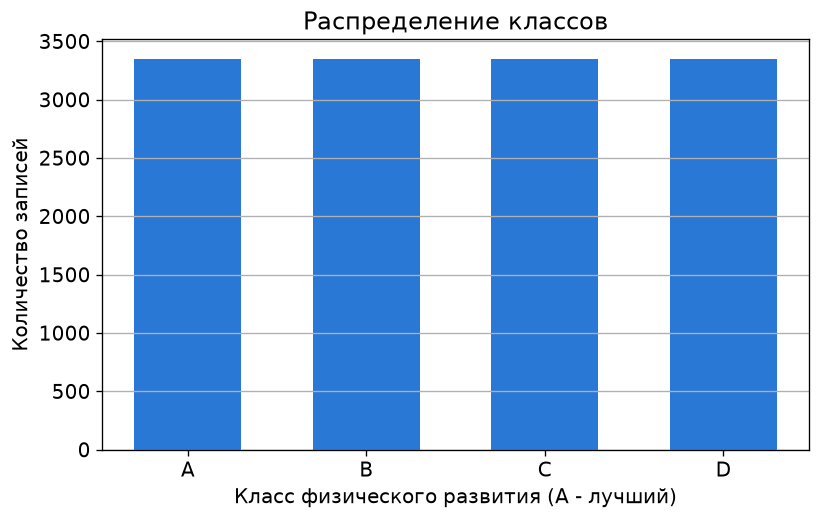

In [7]:
class_counts = raw_data[TARGET].value_counts().reindex(CLASS_NAMES)
print(class_counts.to_string())
print("Доли классов:", (class_counts / len(raw_data)).round(4).to_dict())

figure, axis = plt.subplots(figsize=(7, 4.5))
axis.bar(CLASS_NAMES, class_counts.values, color=TRAIN_COLOR, width=0.6)
axis.set_xlabel("Класс физического развития (A - лучший)")
axis.set_ylabel("Количество записей")
axis.set_title("Распределение классов")
axis.grid(axis="x", visible=False)
figure.tight_layout()
figure.savefig(FIGURES_DIR / "multiclass-class-balance.png")
plt.show()

**Результат:** классы сбалансированы: A 3348, B 3347, C 3349, D 3349, доля каждого около 0,25. Балансировка классов не нужна. Обычная Accuracy здесь почти равна Balanced Accuracy, а Accuracy случайного угадывания равна примерно 0,25.

### Выбросы и невозможные значения

Правило 1,5 IQR показывает необычные значения, но не отличает ошибку от редкого факта. Поэтому дополнительно проверяем физические правила: давление, сила хвата или прыжок не могут быть равны нулю или лежать вне разумных границ.

,Признак,Нижняя граница,Верхняя граница,Записей вне границ,Минимум,Максимум
0,age,-9.50,82.50,0,21.0,64.0
1,height_cm,143.80,193.40,10,125.0,193.8
2,weight_kg,32.55,100.95,83,26.3,138.1
3,body fat_%,3.00,43.00,77,3.0,78.4
4,diastolic,48.50,108.50,54,0.0,156.2
5,systolic,88.50,172.50,29,0.0,201.0
6,gripForce,0.95,71.75,3,0.0,70.5
7,sit and bend forward_cm,-3.80,35.40,409,-25.0,213.0
8,sit-ups counts,0.00,80.00,0,0.0,80.0
9,broad jump_cm,73.50,309.50,57,0.0,303.0


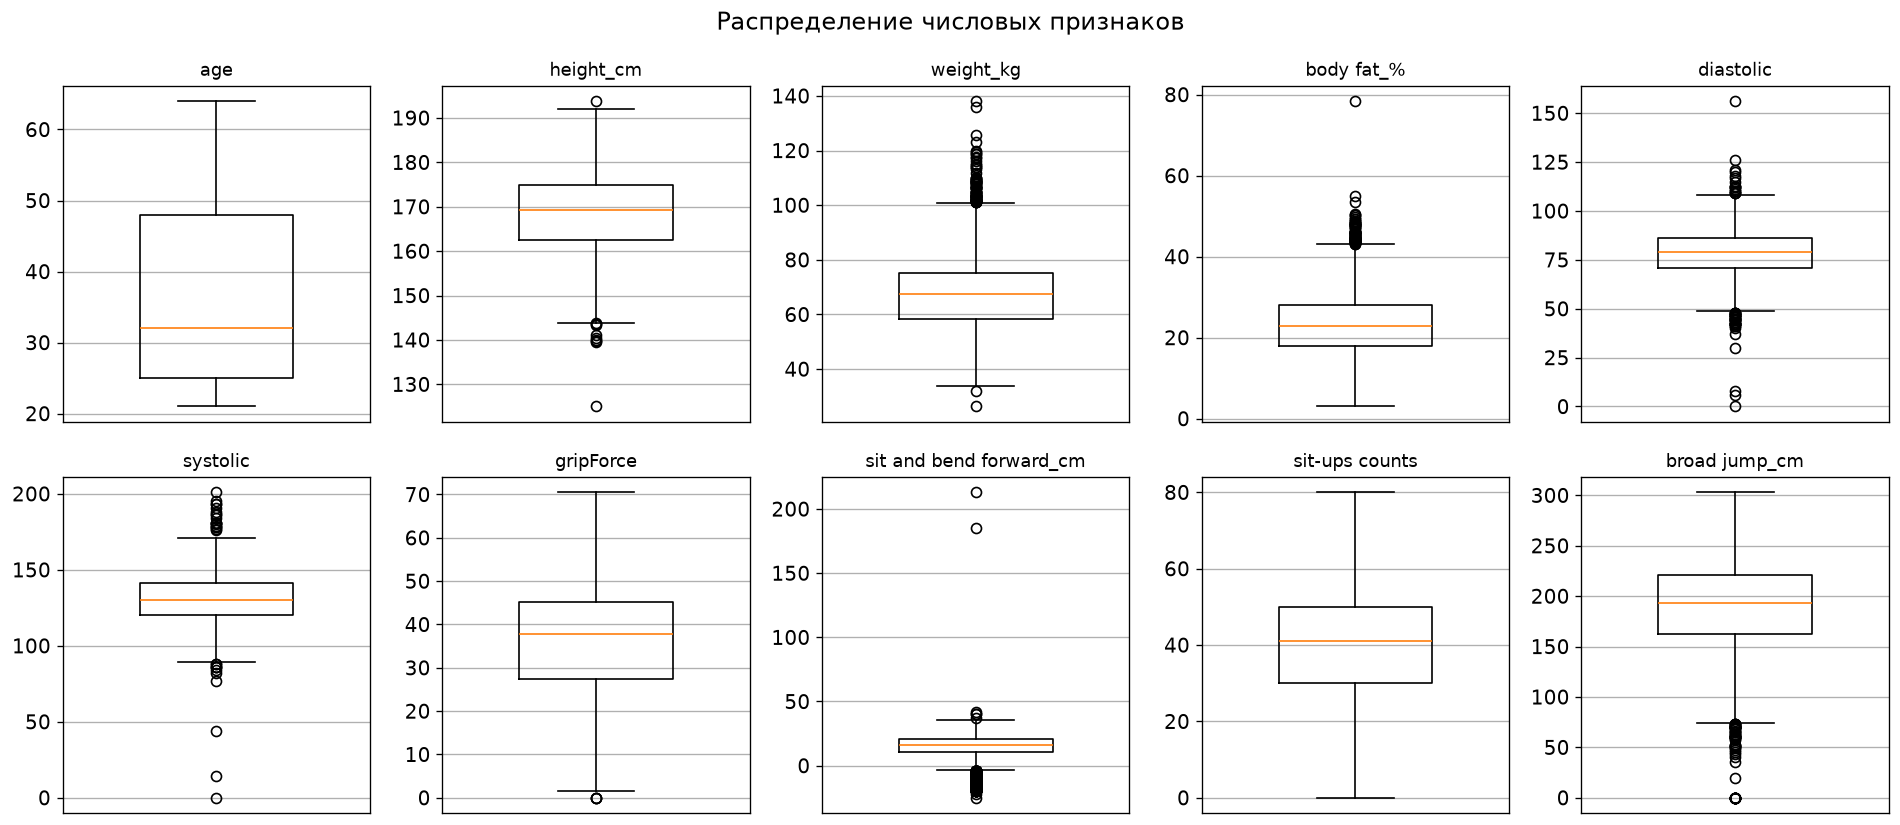

In [8]:
numeric_columns = [column for column in raw_data.columns if column not in ("gender", TARGET)]

# Правило 1,5 IQR считаем только для описания данных
outlier_rows = []
for column in numeric_columns:
    first_quartile, third_quartile = raw_data[column].quantile([0.25, 0.75])
    iqr = third_quartile - first_quartile
    lower_bound = first_quartile - 1.5 * iqr
    upper_bound = third_quartile + 1.5 * iqr
    outside_count = int(((raw_data[column] < lower_bound) | (raw_data[column] > upper_bound)).sum())
    outlier_rows.append({"Признак": column, "Нижняя граница": round(lower_bound, 2),
                         "Верхняя граница": round(upper_bound, 2), "Записей вне границ": outside_count,
                         "Минимум": raw_data[column].min(), "Максимум": raw_data[column].max()})
display(pd.DataFrame(outlier_rows))

figure, axes = plt.subplots(2, 5, figsize=(16, 7))
for axis, column in zip(axes.ravel(), numeric_columns):
    axis.boxplot(raw_data[column], widths=0.5)
    axis.set_title(column, fontsize=11)
    axis.set_xticks([])
figure.suptitle("Распределение числовых признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "multiclass-outliers.png")
plt.show()

In [9]:
def impossible_value_masks(frame):
    """Возвращает словарь: признак -> маска записей с физически невозможным значением.

    Правила фиксированы заранее и не используют статистику выборки, поэтому
    их можно применять к любой части данных без риска утечки.
    """
    return {
        "diastolic": (frame["diastolic"] < 40) | (frame["diastolic"] >= frame["systolic"]),
        "systolic": (frame["systolic"] < 70) | (frame["diastolic"] >= frame["systolic"]),
        "gripForce": frame["gripForce"] == 0,
        "broad jump_cm": frame["broad jump_cm"] == 0,
        "sit and bend forward_cm": (frame["sit and bend forward_cm"] > 50)
        | (frame["sit and bend forward_cm"] < -20),
    }


for column, mask in impossible_value_masks(raw_data).items():
    print(f"{column}: {int(mask.sum())} записей с невозможным значением")
print("Записей с sit-ups counts = 0:", int((raw_data["sit-ups counts"] == 0).sum()),
      "(оставляем: человек мог не выполнить ни одного подъема)")

diastolic: 9 записей с невозможным значением
systolic: 5 записей с невозможным значением
gripForce: 3 записей с невозможным значением
broad jump_cm: 10 записей с невозможным значением
sit and bend forward_cm: 4 записей с невозможным значением
Записей с sit-ups counts = 0: 125 (оставляем: человек мог не выполнить ни одного подъема)


**Результат:** правило 1,5 IQR отмечает много записей (больше всего `sit and bend forward_cm`: 409), но основная их часть - реальные люди с редкими показателями, их не удаляем. Физические правила находят настоящие ошибки: `diastolic` 9 записей, `systolic` 5, `gripForce` 3, `broad jump_cm` 10, `sit and bend forward_cm` 4. 125 записей с `sit-ups counts` = 0 оставляем: это возможный результат.

### Матрица корреляций и связь признаков с классом

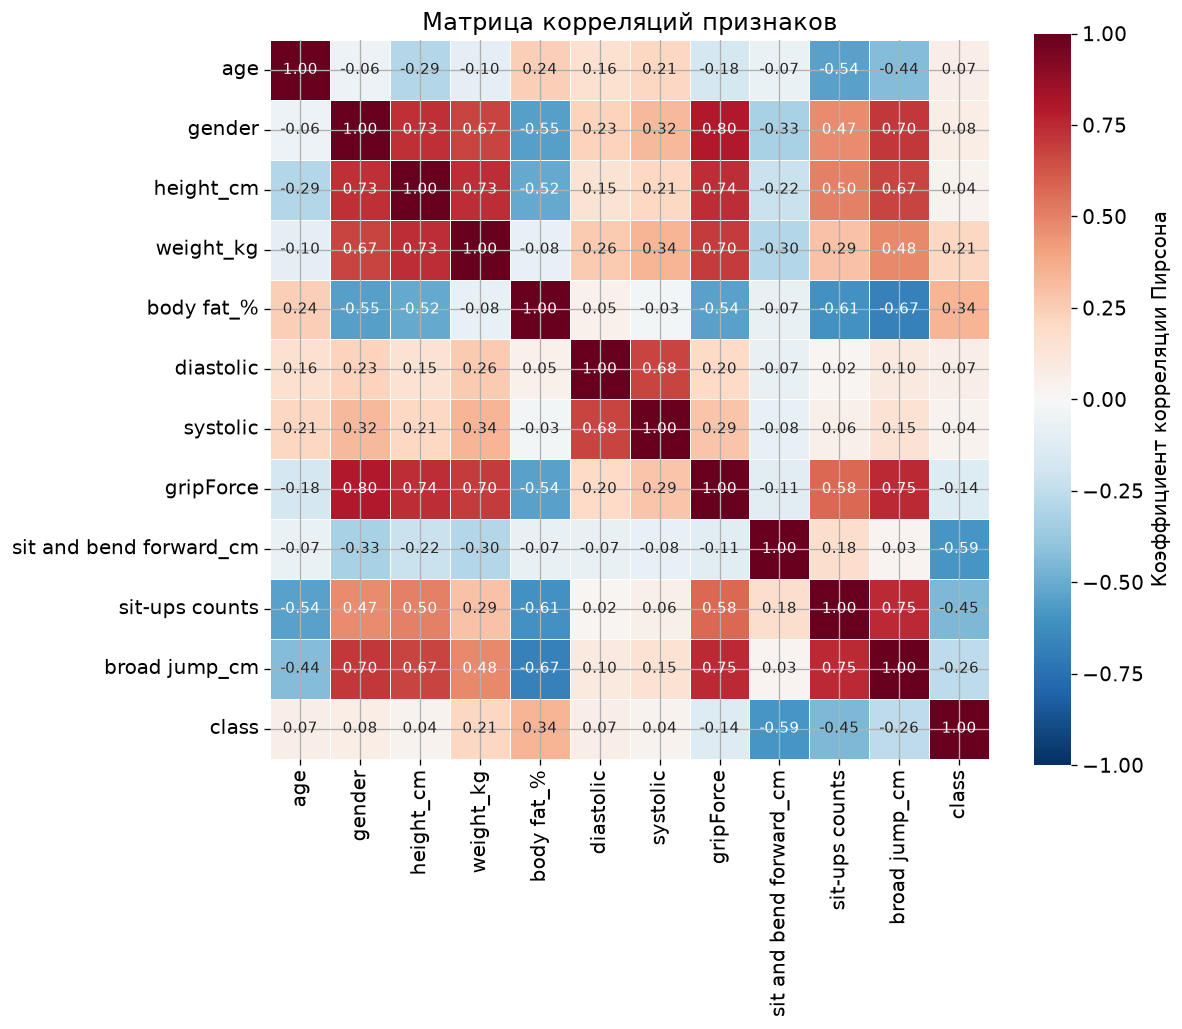

sit and bend forward_cm   -0.588
sit-ups counts            -0.453
body fat_%                 0.342
broad jump_cm             -0.262
weight_kg                  0.214
gripForce                 -0.136
gender                     0.076
diastolic                  0.067
age                        0.066
height_cm                  0.038
systolic                   0.035


In [10]:
# Для корреляции временно кодируем класс порядковым числом: A=0 ... D=3, пол: F=0, M=1
correlation_frame = raw_data.copy()
correlation_frame["gender"] = (correlation_frame["gender"] == "M").astype(int)
correlation_frame[TARGET] = correlation_frame[TARGET].map({name: code for code, name in enumerate(CLASS_NAMES)})
correlation_matrix = correlation_frame.corr()

figure, axis = plt.subplots(figsize=(10, 8.5))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, annot_kws={"size": 9},
            cbar_kws={"label": "Коэффициент корреляции Пирсона"}, ax=axis)
axis.set_title("Матрица корреляций признаков")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "multiclass-correlation.png")
plt.show()

print(correlation_matrix[TARGET].drop(TARGET).sort_values(key=np.abs, ascending=False).round(3).to_string())

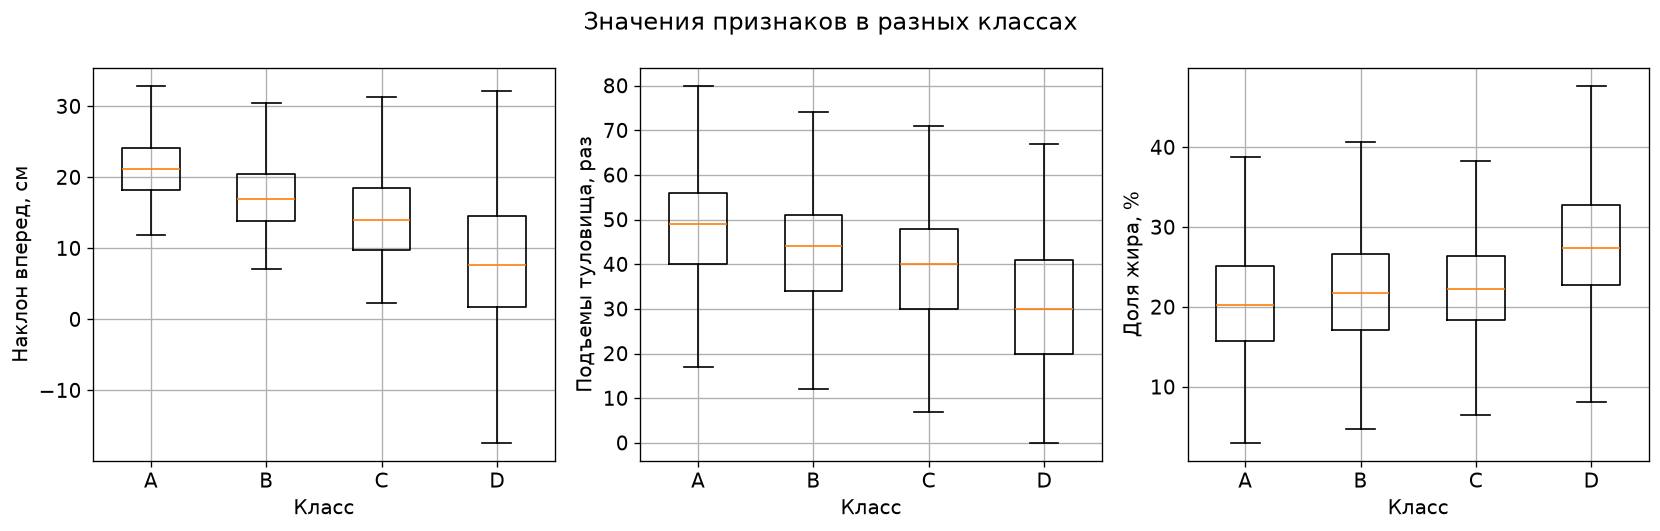

In [11]:
# Распределение трех самых связанных с классом признаков по классам
figure, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for axis, column, label in zip(axes, ["sit and bend forward_cm", "sit-ups counts", "body fat_%"],
                               ["Наклон вперед, см", "Подъемы туловища, раз", "Доля жира, %"]):
    class_values = [raw_data.loc[raw_data[TARGET] == name, column] for name in CLASS_NAMES]
    axis.boxplot(class_values, tick_labels=CLASS_NAMES, widths=0.5, showfliers=False)
    axis.set_xlabel("Класс")
    axis.set_ylabel(label)
figure.suptitle("Значения признаков в разных классах")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "multiclass-features-by-class.png")
plt.show()

**Результат:** сильнее всего с классом связаны `sit and bend forward_cm` (-0,588), `sit-ups counts` (-0,453), `body fat_%` (0,342), `broad jump_cm` (-0,262). Знак минус означает: чем выше результат упражнения, тем лучше класс (ближе к A). Диаграммы показывают, что значения в соседних классах сильно перекрываются. Подозрительно высокой корреляции нет, а по описанию набора уровень подтвержден возрастом и результатами упражнений, поэтому такая связь закономерна и утечкой не является: именно эти показатели задача и должна использовать.

## Подготовка данных

### Удаление дубликатов и отбор признаков

Удаляем полный дубликат до разбиения, чтобы одинаковая запись не попала в разные выборки. Идентификаторов в наборе нет. Ни один признак не вычисляется из класса: `class` присвоен по результатам упражнений и возраста, но эти показатели и есть законные входные данные, поэтому оставляем все 11 признаков.

### Невозможные значения

Заменяем их на пропуск по фиксированным физическим правилам. Правила не зависят от выборки, поэтому применяем их к данным целиком до разбиения. Значение для замены (медиану) считаем позже, только на обучающей части.

In [12]:
data = raw_data.drop_duplicates().reset_index(drop=True)
print("Записей после удаления дубликатов:", len(data))

# Сначала вычисляем все маски, а потом меняем значения: правило для diastolic
# и systolic зависит сразу от двух столбцов
masks = impossible_value_masks(data)
for column, mask in masks.items():
    data[column] = data[column].astype(float)
    data.loc[mask, column] = np.nan

print("Пропусков после замены:")
print(data.isna().sum()[data.isna().sum() > 0].to_string())

Записей после удаления дубликатов: 13392
Пропусков после замены:
diastolic                   9
systolic                    5
gripForce                   3
sit and bend forward_cm     4
broad jump_cm              10


### Разбиение на выборки

Разбиваем в два шага 70 / 15 / 15 со стратификацией, `random_state=SEED`. Этот же код используется в лабораторных работах 4 и 5.

In [13]:
feature_columns = [column for column in data.columns if column != TARGET]

X_full = data[feature_columns]

# Кодируем класс: порядок A, B, C, D фиксирован заранее, поэтому кодирование не требует обучения
y_full = data[TARGET].map({name: code for code, name in enumerate(CLASS_NAMES)}).to_numpy()

# Первый шаг: 70% обучающая часть, 30% временный остаток
X_train_raw, X_rest_raw, y_train, y_rest = train_test_split(
    X_full, y_full, test_size=0.30, stratify=y_full, random_state=SEED
)
# Второй шаг: остаток делим пополам на валидационную и тестовую части
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_rest_raw, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED
)

# Повторяем распределение классов: доли должны совпасть во всех выборках
split_rows = {}
for split_name, y_split in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    counts = np.bincount(y_split, minlength=NUMBER_OF_CLASSES)
    split_rows[split_name] = {"Записей": len(y_split),
                              **{f"Класс {name}": int(count) for name, count in zip(CLASS_NAMES, counts)}}
split_summary = pd.DataFrame(split_rows).T
split_summary.to_csv(RESULTS_DIR / "multiclass-split.csv", encoding="utf-8")
split_summary

,Записей,Класс A,Класс B,Класс C,Класс D
train,9374,2343,2343,2344,2344
validation,2009,502,502,502,503
test,2009,502,502,503,502


**Результат:** после удаления одного дубликата осталось 13 392 записи. Выборки: train 9374, validation 2009, test 2009. В каждой выборке классы равны с точностью до одной записи: стратификация сработала. Набор не сокращался.

### Предобработка

- Числовые признаки: пропуски заполняем медианой, затем масштабируем `StandardScaler`.
- `gender`: кодируем числом 0 / 1. Значения всего два, поэтому One-Hot не нужен: один столбец полностью определяет второй.
- Целевой признак кодируем числами 0-3 и используем разреженную категориальную кросс-энтропию (`sparse_categorical_crossentropy`), поэтому one-hot для меток не требуется.

Все параметры обучаются только на обучающей части.

In [14]:
numeric_feature_columns = [column for column in feature_columns if column != "gender"]

# Конвейер для числовых признаков: импутация, затем масштабирование
numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_feature_columns),
    ("gender", OrdinalEncoder(categories=[["F", "M"]]), ["gender"]),
], verbose_feature_names_out=False)

# fit только на train, к остальным частям применяем transform
X_train = preprocessor.fit_transform(X_train_raw).astype("float32")
X_val = preprocessor.transform(X_val_raw).astype("float32")
X_test = preprocessor.transform(X_test_raw).astype("float32")

# Предобработка нужна лабораторным работам 4 и 5, поэтому сохраняем ее рядом с моделями
joblib.dump(preprocessor, MODELS_DIR / "multiclass-preprocessor.joblib")

print("Размеры матриц:", X_train.shape, X_val.shape, X_test.shape)
print("Пропусков в матрицах:", int(np.isnan(X_train).sum() + np.isnan(X_val).sum() + np.isnan(X_test).sum()))

Размеры матриц: (9374, 11) (2009, 11) (2009, 11)
Пропусков в матрицах: 0


## Базовая модель

Метрики задания считаются одной функцией для всех моделей.

Для каждого класса считаем Precision, Recall и F1, затем средние:

$$ macro = \frac{1}{K}\sum_{k=1}^{K} m_k, \quad weighted = \sum_{k=1}^{K} \frac{n_k}{n} m_k $$

Balanced Accuracy - среднее значение Recall по всем классам. ROC-AUC считается по схеме One-vs-Rest: каждый класс по очереди против остальных, по вероятностям.

`Dummy` всегда называет самый частый класс обучающей части. При четырех почти равных классах ее Accuracy около 0,25.

In [15]:
def evaluate_multiclass(y_true, class_probabilities):
    """Считает общие метрики задания по матрице вероятностей классов."""
    predicted_labels = class_probabilities.argmax(axis=1)
    return {
        "Accuracy": round(accuracy_score(y_true, predicted_labels), 4),
        "Balanced Accuracy": round(balanced_accuracy_score(y_true, predicted_labels), 4),
        "Macro F1": round(precision_recall_fscore_support(
            y_true, predicted_labels, average="macro", zero_division=0)[2], 4),
        "Macro ROC-AUC": round(roc_auc_score(y_true, class_probabilities, multi_class="ovr", average="macro"), 4),
    }


def per_class_table(model_name, y_true, class_probabilities):
    """Строит таблицу B задания: Precision, Recall, F1 и AUC по классам, macro и weighted."""
    predicted_labels = class_probabilities.argmax(axis=1)
    labels = list(range(NUMBER_OF_CLASSES))
    precision, recall, f1_value, _ = precision_recall_fscore_support(
        y_true, predicted_labels, labels=labels, zero_division=0)
    macro = precision_recall_fscore_support(y_true, predicted_labels, average="macro", zero_division=0)
    weighted = precision_recall_fscore_support(y_true, predicted_labels, average="weighted", zero_division=0)

    rows = []
    for metric_name, per_class, position in [("Precision", precision, 0), ("Recall", recall, 1), ("F1-score", f1_value, 2)]:
        row = {"Модель": model_name, "Метрика": metric_name}
        row.update({f"Класс {name}": round(value, 4) for name, value in zip(CLASS_NAMES, per_class)})
        row["Macro avg"] = round(macro[position], 4)
        row["Weighted avg"] = round(weighted[position], 4)
        rows.append(row)

    # AUC по классам: один класс против всех остальных
    auc_row = {"Модель": model_name, "Метрика": "ROC-AUC (OvR)"}
    for class_index, name in enumerate(CLASS_NAMES):
        auc_row[f"Класс {name}"] = round(roc_auc_score(y_true == class_index, class_probabilities[:, class_index]), 4)
    auc_row["Macro avg"] = round(roc_auc_score(y_true, class_probabilities, multi_class="ovr", average="macro"), 4)
    auc_row["Weighted avg"] = round(roc_auc_score(y_true, class_probabilities, multi_class="ovr", average="weighted"), 4)
    rows.append(auc_row)
    return pd.DataFrame(rows)


# Dummy обучается на той же обучающей части, что и нейронные сети
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)
dummy_val_probabilities = dummy_model.predict_proba(X_val)
print("Dummy на validation:", evaluate_multiclass(y_val, dummy_val_probabilities))

Dummy на validation: {'Accuracy': 0.2499, 'Balanced Accuracy': 0.25, 'Macro F1': 0.1, 'Macro ROC-AUC': 0.5}


**Результат:** `Dummy` на validation: Accuracy 0,2499, Balanced Accuracy 0,25, Macro F1 0,1, Macro ROC-AUC 0,5. Это уровень случайного угадывания для четырех равных классов, с ним сравниваем все сети.

## Эксперименты

Все модели обучаются при одинаковых условиях, если эксперимент не меняет именно этот параметр:

- функция потерь: разреженная категориальная кросс-энтропия, выходной слой: 4 нейрона с softmax;
- оптимизатор Adam, скорость обучения 0,001, размер пакета 128;
- не более 150 эпох, Early Stopping по `val_loss` с терпением 12 эпох и восстановлением лучших весов.

Сравнение идет только по validation. Главный критерий - macro ROC-AUC, затем Balanced Accuracy. Если выигрыш по AUC меньше 0,001, оставляем более простую модель.

In [16]:
def build_mlp(hidden_units, activation="relu", optimizer_name="adam", learning_rate=LEARNING_RATE,
              dropout_rate=0.0, l2_factor=0.0):
    """Собирает и компилирует MLP для многоклассовой классификации.

    hidden_units - список с числом нейронов в скрытых слоях.
    dropout_rate - доля отключаемых нейронов, 0 означает слой Dropout не добавлять.
    l2_factor - коэффициент L2-регуляризации весов, 0 означает без нее.
    """
    # Сид ставим перед каждой моделью: начальные веса не зависят от порядка экспериментов
    keras.utils.set_random_seed(SEED)

    regularizer = keras.regularizers.L2(l2_factor) if l2_factor > 0 else None

    model = keras.Sequential()
    model.add(keras.layers.Input(shape=(X_train.shape[1],)))
    for units in hidden_units:
        model.add(keras.layers.Dense(units, activation=activation, kernel_regularizer=regularizer))
        if dropout_rate > 0:
            model.add(keras.layers.Dropout(dropout_rate))
    # Softmax превращает выходы в вероятности четырех классов, их сумма равна 1
    model.add(keras.layers.Dense(NUMBER_OF_CLASSES, activation="softmax"))

    # SGD идет с моментом: без него он слишком медленный для сравнения
    if optimizer_name == "adam":
        optimizer = keras.optimizers.Adam(learning_rate)
    elif optimizer_name == "rmsprop":
        optimizer = keras.optimizers.RMSprop(learning_rate)
    elif optimizer_name == "sgd":
        optimizer = keras.optimizers.SGD(learning_rate, momentum=0.9)
    else:
        raise ValueError(f"Неизвестный оптимизатор: {optimizer_name}")

    model.compile(optimizer=optimizer, loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


# Здесь накапливаются результаты всех экспериментов
trained_models = {}
trained_histories = {}
model_configs = {}
experiment_rows = []


def run_experiment(model_name, hidden_units, activation="relu", optimizer_name="adam",
                   learning_rate=LEARNING_RATE, batch_size=BATCH_SIZE, dropout_rate=0.0, l2_factor=0.0,
                   weighted_class=None, max_epochs=MAX_EPOCHS, use_early_stopping=True):
    """Обучает одну модель, сохраняет ее историю и добавляет строку в таблицу экспериментов.

    weighted_class - номер класса, ошибки на котором штрафуются в 1,5 раза сильнее.
    Веса действуют только при обучении, на validation и test не влияют.
    """
    model = build_mlp(hidden_units, activation, optimizer_name, learning_rate, dropout_rate, l2_factor)

    callbacks = []
    if use_early_stopping:
        callbacks.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=PATIENCE, restore_best_weights=True))

    sample_weight = None if weighted_class is None else np.where(y_train == weighted_class, 1.5, 1.0)

    start_time = time.perf_counter()
    history = model.fit(X_train, y_train, sample_weight=sample_weight, validation_data=(X_val, y_val),
                        epochs=max_epochs, batch_size=batch_size, callbacks=callbacks, verbose=0)
    training_seconds = time.perf_counter() - start_time

    # С ранней остановкой веса взяты с лучшей эпохи, без нее - с последней
    epochs_done = len(history.history["loss"])
    used_epoch = int(np.argmin(history.history["val_loss"])) if use_early_stopping else epochs_done - 1

    val_probabilities = model.predict(X_val, batch_size=4096, verbose=0)
    val_metrics = evaluate_multiclass(y_val, val_probabilities)

    trained_models[model_name] = model
    trained_histories[model_name] = history.history
    model_configs[model_name] = {
        "hidden_units": hidden_units, "activation": activation, "optimizer_name": optimizer_name,
        "learning_rate": learning_rate, "batch_size": batch_size, "dropout_rate": dropout_rate,
        "l2_factor": l2_factor, "weighted_class": weighted_class,
    }
    experiment_rows.append({
        "Модель": model_name,
        "Скрытые слои": "-".join(str(units) for units in hidden_units),
        "Активация": activation,
        "Оптимизатор": optimizer_name,
        "lr": learning_rate,
        "batch_size": batch_size,
        "Dropout": dropout_rate,
        "L2": l2_factor,
        "Усиленный класс": "нет" if weighted_class is None else CLASS_NAMES[weighted_class],
        "Параметров": model.count_params(),
        "Эпох": epochs_done,
        "Лучшая эпоха": used_epoch + 1,
        "Секунд": round(training_seconds, 1),
        "train loss": round(history.history["loss"][used_epoch], 4),
        "val loss": round(history.history["val_loss"][used_epoch], 4),
        "train accuracy": round(history.history["accuracy"][used_epoch], 4),
        **val_metrics,
    })
    print(f"{model_name}: эпох {epochs_done}, лучшая {used_epoch + 1}, {training_seconds:.0f} с, {val_metrics}")
    return model


def experiments_table(model_names=None):
    """Возвращает таблицу экспериментов, целиком или для перечисленных моделей."""
    table = pd.DataFrame(experiment_rows)
    if model_names is not None:
        table = table.set_index("Модель").loc[model_names].reset_index()
    return table


def select_simplest_best(candidate_names):
    """Выбирает модель по macro ROC-AUC на validation.

    Модели в пределах AUC_TOLERANCE от лучшей считаются равными. Среди них берем модель
    с наименьшим числом параметров, а при равенстве - стоящую в списке первой.
    """
    table = experiments_table(candidate_names).set_index("Модель")
    close_models = table[table["Macro ROC-AUC"] >= table["Macro ROC-AUC"].max() - AUC_TOLERANCE]
    return close_models["Параметров"].idxmin()


def plot_history(model_name, file_name, test_values=None):
    """Строит кривые loss и accuracy: train и validation на одном графике.

    test_values - словарь с итоговыми значениями на test, рисуются пунктирной линией.
    Для обычных экспериментов его нет: тестовая выборка при подборе не используется.
    """
    history = trained_histories[model_name]
    epochs = np.arange(1, len(history["loss"]) + 1)
    panels = [("loss", "Функция потерь"), ("accuracy", "Accuracy")]

    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for axis, (metric, label) in zip(axes, panels):
        axis.plot(epochs, history[metric], color=TRAIN_COLOR, linewidth=2, label="train")
        axis.plot(epochs, history[f"val_{metric}"], color=VAL_COLOR, linewidth=2, label="validation")
        if test_values is not None:
            axis.axhline(test_values[metric], color=TEST_COLOR, linestyle="--", linewidth=2,
                         label=f"test: {test_values[metric]:.4f}")
        axis.set_xlabel("Эпоха")
        axis.xaxis.set_major_locator(MaxNLocator(integer=True))
        axis.set_ylabel(label)
        axis.legend()
    figure.suptitle(f"Обучение модели {model_name}")
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name)
    plt.show()


def plot_confusion(y_true, class_probabilities, title, file_name):
    """Рисует матрицу ошибок в количествах и возвращает ее значения."""
    matrix = confusion_matrix(y_true, class_probabilities.argmax(axis=1), labels=list(range(NUMBER_OF_CLASSES)))
    figure, axis = plt.subplots(figsize=(5.5, 4.8))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axis,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    axis.set_xlabel("Предсказанный класс")
    axis.set_ylabel("Истинный класс")
    axis.set_title(title)
    figure.tight_layout()
    figure.savefig(FIGURES_DIR / file_name)
    plt.show()
    return matrix

### 1. MLP-1: простейшая сеть

Начинаем с самой простой сети: один скрытый слой из 16 нейронов, ReLU. Dropout не ставим: пока нет признаков переобучения, бороться не с чем.

MLP-1: эпох 150, лучшая 150, 173 с, {'Accuracy': 0.7193, 'Balanced Accuracy': 0.7192, 'Macro F1': 0.7161, 'Macro ROC-AUC': 0.9105}


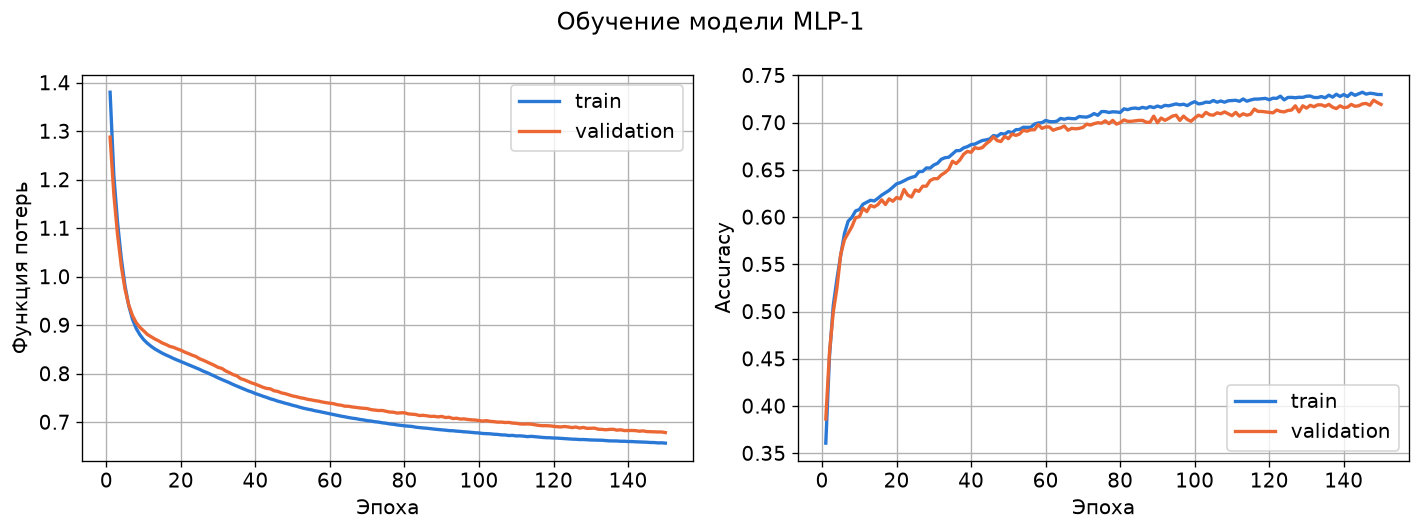

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-1,16,relu,adam,0.001,128,0.0,0.0,нет,260,150,150,172.9,0.6567,0.6784,0.7297,0.7193,0.7192,0.7161,0.9105


In [17]:
run_experiment("MLP-1", hidden_units=[16])
plot_history("MLP-1", "multiclass-mlp-1-history.png")
experiments_table(["MLP-1"])

**Результат:** MLP-1 (260 параметров) на validation: Accuracy 0,7193, Balanced Accuracy 0,7192, Macro F1 0,7161, Macro ROC-AUC 0,9105. Обучение дошло до предела 150 эпох и лучшая эпоха последняя: сеть учится очень медленно. Train loss 0,6567 и val loss 0,6784 близки, переобучения нет. Модель скорее недообучена, поэтому усложнение оправдано.

### 2. MLP-2: средняя сеть

Два скрытых слоя (64 и 32 нейрона). Проверяем, улучшает ли качество возможность выразить взаимодействие признаков.

MLP-2: эпох 76, лучшая 64, 111 с, {'Accuracy': 0.7432, 'Balanced Accuracy': 0.7431, 'Macro F1': 0.7446, 'Macro ROC-AUC': 0.9185}


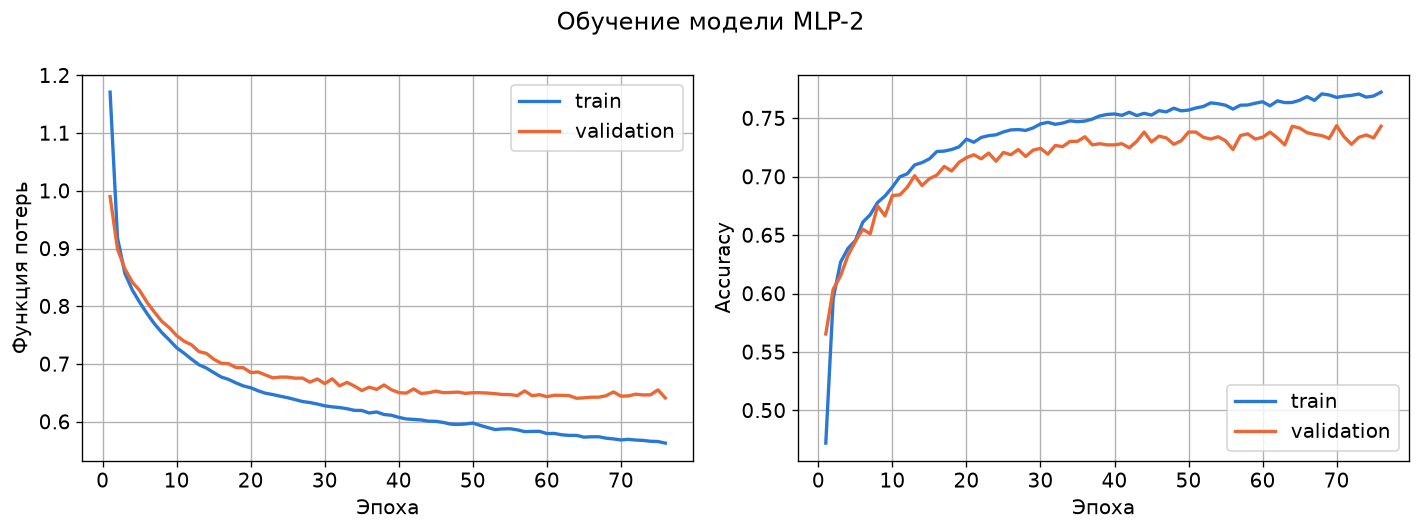

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-1,16,relu,adam,0.001,128,0.0,0.0,нет,260,150,150,172.9,0.6567,0.6784,0.7297,0.7193,0.7192,0.7161,0.9105
1,MLP-2,64-32,relu,adam,0.001,128,0.0,0.0,нет,2980,76,64,111.0,0.5763,0.6406,0.7635,0.7432,0.7431,0.7446,0.9185


In [18]:
run_experiment("MLP-2", hidden_units=[64, 32])
plot_history("MLP-2", "multiclass-mlp-2-history.png")
experiments_table(["MLP-1", "MLP-2"])

**Результат:** MLP-2 (2980 параметров): Balanced Accuracy 0,7431, Macro ROC-AUC 0,9185. Прирост заметный: Balanced Accuracy выросла на 0,024, AUC на 0,008. Train loss 0,5763, val loss 0,6406: разрыв уже больше, ранняя остановка сработала на 76-й эпохе.

### 3. MLP-3: глубокая и широкая сеть

Три скрытых слоя (256, 128 и 64 нейрона). Эта модель проверяет верхнюю границу сложности.

MLP-3: эпох 33, лучшая 21, 42 с, {'Accuracy': 0.7352, 'Balanced Accuracy': 0.7351, 'Macro F1': 0.7341, 'Macro ROC-AUC': 0.9224}


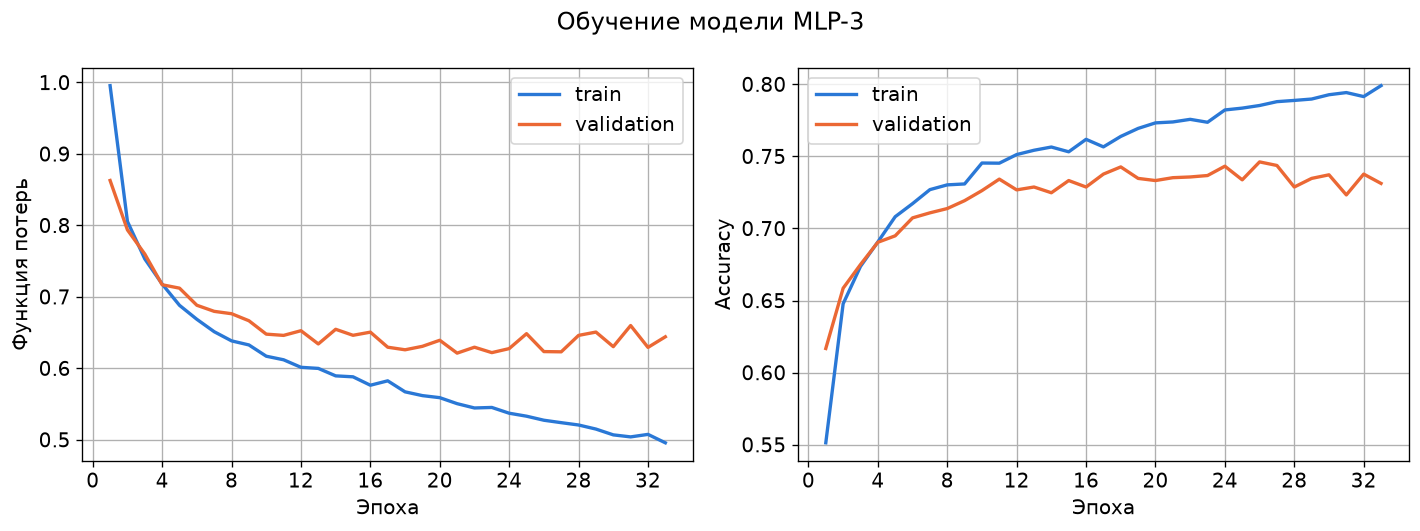

Выбрана архитектура: MLP-3


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-1,16,relu,adam,0.001,128,0.0,0.0,нет,260,150,150,172.9,0.6567,0.6784,0.7297,0.7193,0.7192,0.7161,0.9105
1,MLP-2,64-32,relu,adam,0.001,128,0.0,0.0,нет,2980,76,64,111.0,0.5763,0.6406,0.7635,0.7432,0.7431,0.7446,0.9185
2,MLP-3,256-128-64,relu,adam,0.001,128,0.0,0.0,нет,44484,33,21,42.1,0.5504,0.6212,0.7738,0.7352,0.7351,0.7341,0.9224


In [19]:
run_experiment("MLP-3", hidden_units=[256, 128, 64])
plot_history("MLP-3", "multiclass-mlp-3-history.png")

# Лучшая архитектура определяется автоматически по validation
architecture_names = ["MLP-1", "MLP-2", "MLP-3"]
current_name = select_simplest_best(architecture_names)
current_config = dict(model_configs[current_name])
print("Выбрана архитектура:", current_name)
experiments_table(architecture_names)

**Результат:** MLP-3 (44 484 параметра): Balanced Accuracy 0,7351, Macro ROC-AUC 0,9224. По AUC это лучшая архитектура: выигрыш 0,0039 у MLP-2 больше порога шума 0,001. Обучение остановлено на 33-й эпохе. Разрыв train loss 0,5504 и val loss 0,6212 больше, чем у MLP-2. В отличие от бинарной задачи, здесь рост сложности дает прирост. Вероятно, класс зависит от сочетания показателей с полом и возрастом, а такие взаимодействия лучше выражает глубокая сеть.

### 4. Функция активации

Сравниваем ReLU с tanh на выбранной архитектуре.

In [20]:
tanh_name = f"{current_name}-tanh"
run_experiment(tanh_name, **{**current_config, "activation": "tanh"})

activation_names = [current_name, tanh_name]
current_name = select_simplest_best(activation_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(activation_names)

MLP-3-tanh: эпох 42, лучшая 30, 71 с, {'Accuracy': 0.7442, 'Balanced Accuracy': 0.7441, 'Macro F1': 0.7426, 'Macro ROC-AUC': 0.9211}
Оставляем: MLP-3


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-3,256-128-64,relu,adam,0.001,128,0.0,0.0,нет,44484,33,21,42.1,0.5504,0.6212,0.7738,0.7352,0.7351,0.7341,0.9224
1,MLP-3-tanh,256-128-64,tanh,adam,0.001,128,0.0,0.0,нет,44484,42,30,70.5,0.5615,0.6247,0.7709,0.7442,0.7441,0.7426,0.9211


**Результат:** tanh дает Macro ROC-AUC 0,9211 против 0,9224 у ReLU. Balanced Accuracy немного выше (0,7441 против 0,7351), но главный критерий хуже, поэтому оставляем ReLU. На трехслойной сети ReLU не насыщается и обучается быстрее: 33 эпохи против 42.

### 5. Оптимизатор

Сравниваем Adam с RMSprop и с SGD с моментом 0,9. Скорость обучения SGD равна 0,01: при 0,001 он не успевает сойтись, и сравнение было бы нечестным.

In [21]:
rmsprop_name = f"{current_name}-rmsprop"
sgd_name = f"{current_name}-sgd"
run_experiment(rmsprop_name, **{**current_config, "optimizer_name": "rmsprop"})
run_experiment(sgd_name, **{**current_config, "optimizer_name": "sgd", "learning_rate": 0.01})

optimizer_names = [current_name, rmsprop_name, sgd_name]
current_name = select_simplest_best(optimizer_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(optimizer_names)

MLP-3-rmsprop: эпох 39, лучшая 27, 57 с, {'Accuracy': 0.7292, 'Balanced Accuracy': 0.7292, 'Macro F1': 0.7266, 'Macro ROC-AUC': 0.9179}


MLP-3-sgd: эпох 67, лучшая 55, 80 с, {'Accuracy': 0.7377, 'Balanced Accuracy': 0.7376, 'Macro F1': 0.7344, 'Macro ROC-AUC': 0.9224}
Оставляем: MLP-3


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-3,256-128-64,relu,adam,0.001,128,0.0,0.0,нет,44484,33,21,42.1,0.5504,0.6212,0.7738,0.7352,0.7351,0.7341,0.9224
1,MLP-3-rmsprop,256-128-64,relu,rmsprop,0.001,128,0.0,0.0,нет,44484,39,27,57.1,0.5350,0.6450,0.7809,0.7292,0.7292,0.7266,0.9179
2,MLP-3-sgd,256-128-64,relu,sgd,0.010,128,0.0,0.0,нет,44484,67,55,79.5,0.5201,0.6306,0.7868,0.7377,0.7376,0.7344,0.9224


**Результат:** Adam 0,9224, RMSprop 0,9179, SGD с моментом 0,9224. SGD сравнялся с Adam по AUC, но ему нужно 67 эпох вместо 33, и Adam при равенстве остается первым в списке. У RMSprop самый большой val loss из трех вариантов (0,6450). Оставляем Adam.

### 6. Скорость обучения и размер пакета

Слишком большой шаг мешает сойтись к минимуму, слишком маленький не успевает дойти до него. Размер пакета меняет число обновлений весов за эпоху и шум градиента.

In [22]:
lr_high_name = f"{current_name}-lr0.01"
lr_low_name = f"{current_name}-lr0.0001"
batch_small_name = f"{current_name}-batch64"
batch_large_name = f"{current_name}-batch512"
run_experiment(lr_high_name, **{**current_config, "learning_rate": 0.01})
run_experiment(lr_low_name, **{**current_config, "learning_rate": 0.0001})
run_experiment(batch_small_name, **{**current_config, "batch_size": 64})
run_experiment(batch_large_name, **{**current_config, "batch_size": 512})

training_names = [current_name, lr_high_name, lr_low_name, batch_small_name, batch_large_name]
current_name = select_simplest_best(training_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(training_names)

MLP-3-lr0.01: эпох 29, лучшая 17, 43 с, {'Accuracy': 0.7451, 'Balanced Accuracy': 0.7451, 'Macro F1': 0.7458, 'Macro ROC-AUC': 0.9238}


MLP-3-lr0.0001: эпох 150, лучшая 149, 246 с, {'Accuracy': 0.7267, 'Balanced Accuracy': 0.7267, 'Macro F1': 0.7255, 'Macro ROC-AUC': 0.9188}


MLP-3-batch64: эпох 30, лучшая 18, 68 с, {'Accuracy': 0.7402, 'Balanced Accuracy': 0.7401, 'Macro F1': 0.7408, 'Macro ROC-AUC': 0.9214}


MLP-3-batch512: эпох 47, лучшая 35, 15 с, {'Accuracy': 0.7387, 'Balanced Accuracy': 0.7386, 'Macro F1': 0.7377, 'Macro ROC-AUC': 0.9207}
Оставляем: MLP-3-lr0.01


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-3,256-128-64,relu,adam,0.0010,128,0.0,0.0,нет,44484,33,21,42.1,0.5504,0.6212,0.7738,0.7352,0.7351,0.7341,0.9224
1,MLP-3-lr0.01,256-128-64,relu,adam,0.0100,128,0.0,0.0,нет,44484,29,17,43.5,0.5779,0.6179,0.7572,0.7451,0.7451,0.7458,0.9238
2,MLP-3-lr0.0001,256-128-64,relu,adam,0.0001,128,0.0,0.0,нет,44484,150,149,246.5,0.5218,0.6376,0.7925,0.7267,0.7267,0.7255,0.9188
3,MLP-3-batch64,256-128-64,relu,adam,0.0010,64,0.0,0.0,нет,44484,30,18,68.3,0.5494,0.6266,0.7726,0.7402,0.7401,0.7408,0.9214
4,MLP-3-batch512,256-128-64,relu,adam,0.0010,512,0.0,0.0,нет,44484,47,35,14.7,0.5562,0.6298,0.7735,0.7387,0.7386,0.7377,0.9207


**Результат:** скорость 0,01 дала лучший Macro ROC-AUC 0,9238 и Balanced Accuracy 0,7451 за 29 эпох, выигрыш 0,0014 больше порога шума. Скорость 0,0001 дала 0,9188 и исчерпала 150 эпох. Пакеты 64 и 512 дали 0,9214 и 0,9207, хуже базовых 128. Дальше используем MLP-3-lr0.01. Вероятно, большой шаг мешает сети запоминать обучающую часть: у нее самый высокий train loss среди вариантов этого эксперимента (0,5779).

### 7. Проверка переобучения и регуляризация

Ранняя остановка скрывает переобучение: обучение заканчивается раньше, чем оно становится заметным. Поэтому сначала обучаем самую большую сеть MLP-3 без ранней остановки и смотрим кривые. Затем проверяем, помогает ли Dropout (0,3) и L2-регуляризация (0,0001).

MLP-3-no-es: эпох 80, лучшая 80, 94 с, {'Accuracy': 0.7178, 'Balanced Accuracy': 0.7177, 'Macro F1': 0.7139, 'Macro ROC-AUC': 0.9044}


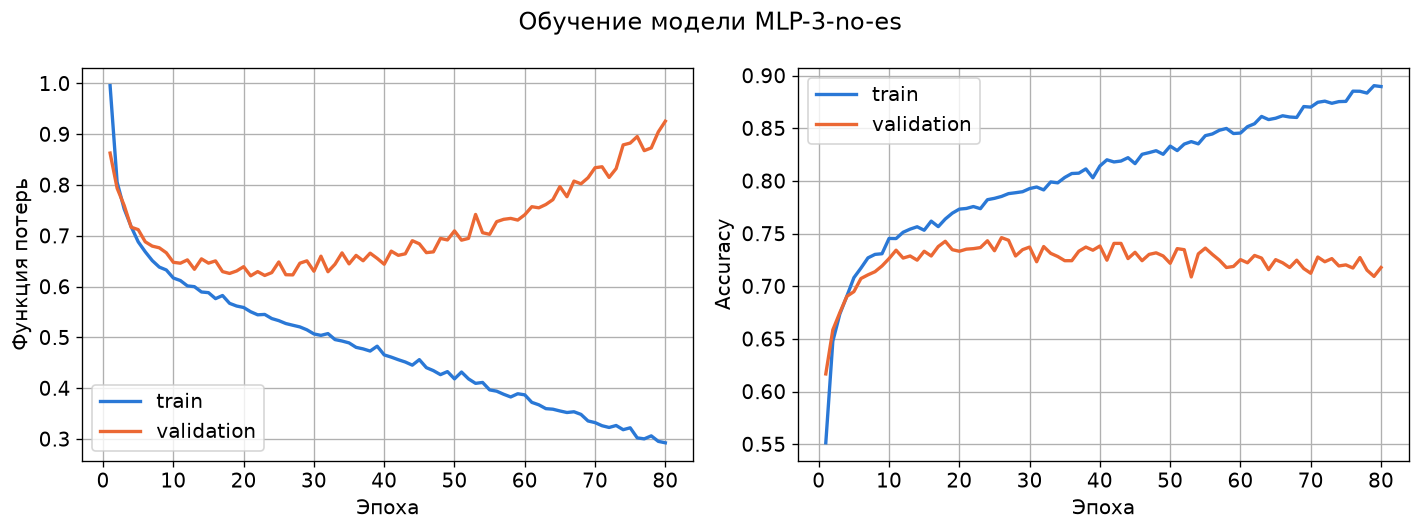

MLP-3-no-es-dropout: эпох 80, лучшая 80, 102 с, {'Accuracy': 0.7377, 'Balanced Accuracy': 0.7377, 'Macro F1': 0.7399, 'Macro ROC-AUC': 0.9217}


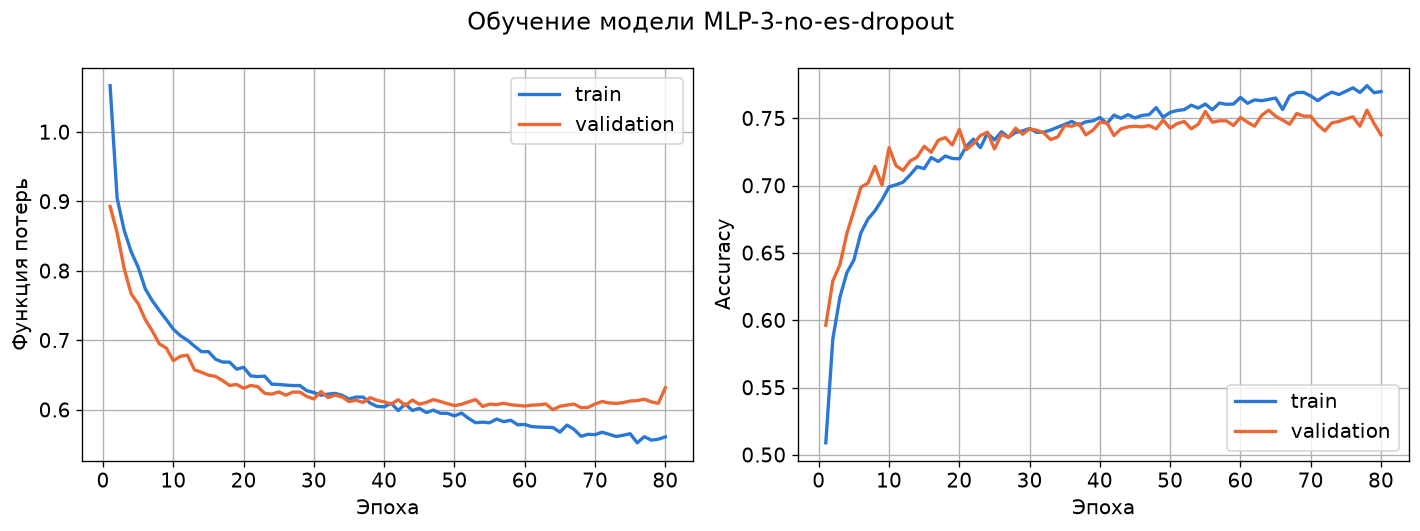

,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-3,256-128-64,relu,adam,0.001,128,0.0,0.0,нет,44484,33,21,42.1,0.5504,0.6212,0.7738,0.7352,0.7351,0.7341,0.9224
1,MLP-3-no-es,256-128-64,relu,adam,0.001,128,0.0,0.0,нет,44484,80,80,94.1,0.2924,0.9256,0.8896,0.7178,0.7177,0.7139,0.9044
2,MLP-3-no-es-dropout,256-128-64,relu,adam,0.001,128,0.3,0.0,нет,44484,80,80,102.2,0.5609,0.6317,0.7699,0.7377,0.7377,0.7399,0.9217


In [23]:
# Большая сеть без ранней остановки: показываем, как выглядит переобучение на этих данных
overfit_config = dict(model_configs["MLP-3"])
run_experiment("MLP-3-no-es", **overfit_config, max_epochs=80, use_early_stopping=False)
plot_history("MLP-3-no-es", "multiclass-overfit-history.png")

# Та же сеть с Dropout и тоже без ранней остановки
run_experiment("MLP-3-no-es-dropout", **{**overfit_config, "dropout_rate": 0.3}, max_epochs=80,
               use_early_stopping=False)
plot_history("MLP-3-no-es-dropout", "multiclass-dropout-history.png")
experiments_table(["MLP-3", "MLP-3-no-es", "MLP-3-no-es-dropout"])

In [24]:
# Те же приемы на текущей лучшей модели, с обычными условиями обучения
dropout_name = f"{current_name}-dropout"
l2_name = f"{current_name}-l2"
run_experiment(dropout_name, **{**current_config, "dropout_rate": 0.3})
run_experiment(l2_name, **{**current_config, "l2_factor": 0.0001})

regularization_names = [current_name, dropout_name, l2_name]
current_name = select_simplest_best(regularization_names)
current_config = dict(model_configs[current_name])
print("Оставляем:", current_name)
experiments_table(regularization_names)

MLP-3-lr0.01-dropout: эпох 73, лучшая 61, 121 с, {'Accuracy': 0.7367, 'Balanced Accuracy': 0.7366, 'Macro F1': 0.7332, 'Macro ROC-AUC': 0.9199}


MLP-3-lr0.01-l2: эпох 30, лучшая 18, 49 с, {'Accuracy': 0.7432, 'Balanced Accuracy': 0.7431, 'Macro F1': 0.7413, 'Macro ROC-AUC': 0.9249}
Оставляем: MLP-3-lr0.01-l2


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-3-lr0.01,256-128-64,relu,adam,0.01,128,0.0,0.0000,нет,44484,29,17,43.5,0.5779,0.6179,0.7572,0.7451,0.7451,0.7458,0.9238
1,MLP-3-lr0.01-dropout,256-128-64,relu,adam,0.01,128,0.3,0.0000,нет,44484,73,61,121.5,0.6724,0.6324,0.7240,0.7367,0.7366,0.7332,0.9199
2,MLP-3-lr0.01-l2,256-128-64,relu,adam,0.01,128,0.0,0.0001,нет,44484,30,18,49.3,0.6223,0.6378,0.7550,0.7432,0.7431,0.7413,0.9249


**Результат:** переобучение здесь выражено сильно. У MLP-3-no-es к 80-й эпохе train loss упал до 0,2924, val loss вырос до 0,9256, train accuracy 0,8896 против 0,7178 на validation, кривые на графике разошлись примерно после 20-й эпохи. Dropout 0,3 это исправил: train loss 0,5609, val loss 0,6317, Macro ROC-AUC 0,9217 вместо 0,9044. Значит, Dropout на этих данных нужен, если нет ранней остановки.

На текущей лучшей модели с ранней остановкой: Dropout снизил Macro ROC-AUC с 0,9238 до 0,9199 (ранняя остановка уже решает эту задачу, а Dropout замедляет обучение: 73 эпохи). L2 0,0001 подняла его до 0,9249, выигрыш 0,0011 больше порога. Оставляем MLP-3-lr0.01-l2. Обратите внимание: функция потерь этой модели содержит штраф L2, поэтому ее значения нельзя напрямую сравнивать с loss моделей без L2.

### 8. Анализ матрицы ошибок

Смотрим, какие классы путает текущая лучшая модель на validation. Классы упорядочены от A к D, поэтому ожидаем ошибки между соседними классами.

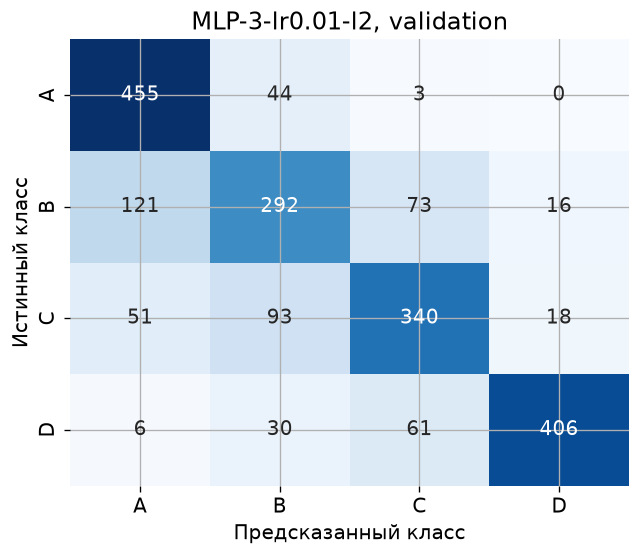

Всего ошибок: 516
Ошибок между соседними классами: 410


,Модель,Метрика,Класс A,Класс B,Класс C,Класс D,Macro avg,Weighted avg
0,MLP-3-lr0.01-l2,Precision,0.7188,0.6362,0.7128,0.9227,0.7476,0.7477
1,MLP-3-lr0.01-l2,Recall,0.9064,0.5817,0.6773,0.8072,0.7431,0.7432
2,MLP-3-lr0.01-l2,F1-score,0.8018,0.6077,0.6946,0.8611,0.7413,0.7413
3,MLP-3-lr0.01-l2,ROC-AUC (OvR),0.9526,0.8786,0.8981,0.9701,0.9249,0.9249


In [25]:
base_val_probabilities = trained_models[current_name].predict(X_val, batch_size=4096, verbose=0)
before_matrix = plot_confusion(y_val, base_val_probabilities, f"{current_name}, validation",
                               "multiclass-confusion-before.png")

# Доля ошибок, которые приходятся на соседние классы, например B вместо C
error_mask = ~np.eye(NUMBER_OF_CLASSES, dtype=bool)
adjacent_mask = np.abs(np.subtract.outer(np.arange(NUMBER_OF_CLASSES), np.arange(NUMBER_OF_CLASSES))) == 1
print("Всего ошибок:", before_matrix[error_mask].sum())
print("Ошибок между соседними классами:", before_matrix[adjacent_mask].sum())
per_class_table(current_name, y_val, base_val_probabilities)

**Результат:** на validation Recall классов: A 0,9064, B 0,5817, C 0,6773, D 0,8072. Хуже всего распознается класс B, потом C. Крайние классы A и D распознаются лучше: у них только один сосед. На соседние классы приходится 410 из 516 ошибок (79%). Чаще всего класс B называется A (121 объект), класс C называется B (93), класс B называется C (73), класс D называется C (61). Вероятная причина: классы упорядочены, а граница между ними условная, поэтому люди у границы классов имеют почти одинаковые значения признаков.

Классы сбалансированы, поэтому `class_weight` здесь бессмыслен. Проблемные классы - средние (B и C): у них два соседа, а граница между классами условна. Проверяем обоснованный способ усилить именно эти классы: увеличиваем вес ошибок на классе с самым низким Recall на validation в 1,5 раза. Это проверка гипотезы: если путаница вызвана нехваткой внимания модели к классу, Recall вырастет без падения общих метрик. Веса применяются только к обучающей части.

Recall по классам до изменения: {'A': np.float64(0.9064), 'B': np.float64(0.5817), 'C': np.float64(0.6773), 'D': np.float64(0.8072)}
Самый слабый класс: B


MLP-3-lr0.01-l2-weight-B: эпох 30, лучшая 18, 42 с, {'Accuracy': 0.7332, 'Balanced Accuracy': 0.7332, 'Macro F1': 0.7359, 'Macro ROC-AUC': 0.9231}


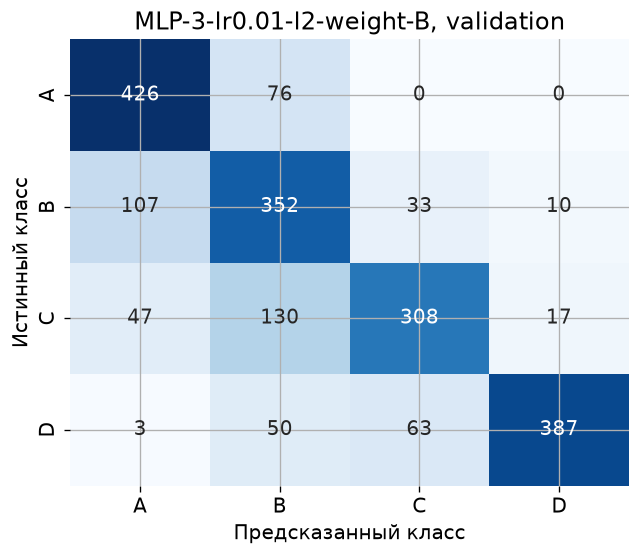

,До,После
Accuracy,0.7432,0.7332
Balanced Accuracy,0.7431,0.7332
Macro F1,0.7413,0.7359
Macro ROC-AUC,0.9249,0.9231
Recall A,0.9064,0.8486
Recall B,0.5817,0.7012
Recall C,0.6773,0.6135
Recall D,0.8072,0.7694


In [26]:
# Класс с самым низким Recall определяем по validation
before_recall = np.diag(before_matrix) / before_matrix.sum(axis=1)
weakest_class = int(before_recall.argmin())
print("Recall по классам до изменения:", dict(zip(CLASS_NAMES, before_recall.round(4))))
print("Самый слабый класс:", CLASS_NAMES[weakest_class])

weighted_name = f"{current_name}-weight-{CLASS_NAMES[weakest_class]}"
run_experiment(weighted_name, **{**current_config, "weighted_class": weakest_class})

weighted_val_probabilities = trained_models[weighted_name].predict(X_val, batch_size=4096, verbose=0)
weighted_matrix = plot_confusion(y_val, weighted_val_probabilities, f"{weighted_name}, validation",
                                 "multiclass-confusion-after.png")
after_recall = np.diag(weighted_matrix) / weighted_matrix.sum(axis=1)

# Сравнение до и после на validation
comparison = pd.DataFrame({
    "До": {**evaluate_multiclass(y_val, base_val_probabilities),
           **{f"Recall {name}": round(value, 4) for name, value in zip(CLASS_NAMES, before_recall)}},
    "После": {**evaluate_multiclass(y_val, weighted_val_probabilities),
              **{f"Recall {name}": round(value, 4) for name, value in zip(CLASS_NAMES, after_recall)}},
})
comparison.to_csv(RESULTS_DIR / "multiclass-confusion-fix.csv", encoding="utf-8")
comparison

**Результат:** повышение веса класса B в 1,5 раза подняло Recall B с 0,5817 до 0,7012, но Recall A упал с 0,9064 до 0,8486, C с 0,6773 до 0,6135, D с 0,8072 до 0,7694. Общие метрики ухудшились: Balanced Accuracy с 0,7431 до 0,7332, Macro ROC-AUC с 0,9249 до 0,9231. Значит, ошибки не исчезли, а перешли в другие классы: дело не в недостатке внимания к классу B, а в перекрытии признаков соседних классов. Эту модель не выбираем. Аугментация тут тоже не подходит: классы сбалансированы и данных хватает, а граница между классами от новых примеров четче не станет.

### 9. Сводная таблица экспериментов

Все исследованные модели с параметрами и метриками на validation. Итоговая модель - лучшая по macro ROC-AUC среди всех моделей с ранней остановкой, при равенстве более простая. Таблица сохраняется в `results/multiclass-experiments.csv`.

In [27]:
# Модели без ранней остановки нужны были только для показа переобучения
selectable_names = [row["Модель"] for row in experiment_rows if "no-es" not in row["Модель"]]
final_name = select_simplest_best(selectable_names)
final_model = trained_models[final_name]
print("Итоговая модель:", final_name)

all_experiments = experiments_table()
all_experiments.to_csv(RESULTS_DIR / "multiclass-experiments.csv", index=False, encoding="utf-8")

# Истории обучения трех основных архитектур и итоговой модели сохраняем для отчета
for file_suffix, model_name in [("mlp-1", "MLP-1"), ("mlp-2", "MLP-2"), ("mlp-3", "MLP-3"), ("best", final_name)]:
    pd.DataFrame(trained_histories[model_name]).round(4).to_csv(
        RESULTS_DIR / f"multiclass-history-{file_suffix}.csv", index_label="epoch", encoding="utf-8")

pd.set_option("display.max_columns", None, "display.width", 250)
all_experiments

Итоговая модель: MLP-3-lr0.01-l2


,Модель,Скрытые слои,Активация,Оптимизатор,lr,batch_size,Dropout,L2,Усиленный класс,Параметров,Эпох,Лучшая эпоха,Секунд,train loss,val loss,train accuracy,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC
0,MLP-1,16,relu,adam,0.0010,128,0.0,0.0000,нет,260,150,150,172.9,0.6567,0.6784,0.7297,0.7193,0.7192,0.7161,0.9105
1,MLP-2,64-32,relu,adam,0.0010,128,0.0,0.0000,нет,2980,76,64,111.0,0.5763,0.6406,0.7635,0.7432,0.7431,0.7446,0.9185
2,MLP-3,256-128-64,relu,adam,0.0010,128,0.0,0.0000,нет,44484,33,21,42.1,0.5504,0.6212,0.7738,0.7352,0.7351,0.7341,0.9224
3,MLP-3-tanh,256-128-64,tanh,adam,0.0010,128,0.0,0.0000,нет,44484,42,30,70.5,0.5615,0.6247,0.7709,0.7442,0.7441,0.7426,0.9211
4,MLP-3-rmsprop,256-128-64,relu,rmsprop,0.0010,128,0.0,0.0000,нет,44484,39,27,57.1,0.5350,0.6450,0.7809,0.7292,0.7292,0.7266,0.9179
5,MLP-3-sgd,256-128-64,relu,sgd,0.0100,128,0.0,0.0000,нет,44484,67,55,79.5,0.5201,0.6306,0.7868,0.7377,0.7376,0.7344,0.9224
6,MLP-3-lr0.01,256-128-64,relu,adam,0.0100,128,0.0,0.0000,нет,44484,29,17,43.5,0.5779,0.6179,0.7572,0.7451,0.7451,0.7458,0.9238
7,MLP-3-lr0.0001,256-128-64,relu,adam,0.0001,128,0.0,0.0000,нет,44484,150,149,246.5,0.5218,0.6376,0.7925,0.7267,0.7267,0.7255,0.9188
8,MLP-3-batch64,256-128-64,relu,adam,0.0010,64,0.0,0.0000,нет,44484,30,18,68.3,0.5494,0.6266,0.7726,0.7402,0.7401,0.7408,0.9214
9,MLP-3-batch512,256-128-64,relu,adam,0.0010,512,0.0,0.0000,нет,44484,47,35,14.7,0.5562,0.6298,0.7735,0.7387,0.7386,0.7377,0.9207


## Итоговая оценка на тестовой выборке

Выбор модели закончен, все решения приняты по validation. Теперь один раз считаем метрики всех моделей на test как отчет. После этой таблицы модели не меняются.

Таблица общих метрик по всем моделям:

In [28]:
test_probabilities_by_model = {
    model_name: model.predict(X_test, batch_size=4096, verbose=0) for model_name, model in trained_models.items()
}

summary_rows = []
for model_name, test_probabilities in test_probabilities_by_model.items():
    note = "итоговая модель" if model_name == final_name else ""
    summary_rows.append({"Модель": model_name, **evaluate_multiclass(y_test, test_probabilities), "Примечание": note})
dummy_test_probabilities = dummy_model.predict_proba(X_test)
summary_rows.append({"Модель": "Dummy", **evaluate_multiclass(y_test, dummy_test_probabilities),
                     "Примечание": "базовая модель"})

test_summary = pd.DataFrame(summary_rows)
test_summary.to_csv(RESULTS_DIR / "multiclass-metrics.csv", index=False, encoding="utf-8")
test_summary

,Модель,Accuracy,Balanced Accuracy,Macro F1,Macro ROC-AUC,Примечание
0,MLP-1,0.7277,0.7278,0.7237,0.9163,
1,MLP-2,0.7427,0.7427,0.7426,0.9190,
2,MLP-3,0.7466,0.7467,0.7440,0.9244,
3,MLP-3-tanh,0.7402,0.7402,0.7376,0.9226,
4,MLP-3-rmsprop,0.7327,0.7328,0.7292,0.9169,
5,MLP-3-sgd,0.7576,0.7576,0.7536,0.9257,
6,MLP-3-lr0.01,0.7466,0.7467,0.7470,0.9203,
7,MLP-3-lr0.0001,0.7437,0.7437,0.7416,0.9204,
8,MLP-3-batch64,0.7546,0.7546,0.7550,0.9251,
9,MLP-3-batch512,0.7481,0.7482,0.7467,0.9220,


Таблица B задания: метрики по классам для трех архитектур и итоговой модели. Полная таблица по всем моделям сохраняется в `results/multiclass-per-class.csv`.

In [29]:
per_class_tables = [per_class_table(model_name, y_test, test_probabilities)
                    for model_name, test_probabilities in test_probabilities_by_model.items()]
per_class_tables.append(per_class_table("Dummy", y_test, dummy_test_probabilities))
per_class_metrics = pd.concat(per_class_tables, ignore_index=True)
per_class_metrics.to_csv(RESULTS_DIR / "multiclass-per-class.csv", index=False, encoding="utf-8")

shown_models = list(dict.fromkeys(["MLP-1", "MLP-2", "MLP-3", final_name]))
per_class_metrics[per_class_metrics["Модель"].isin(shown_models)]

,Модель,Метрика,Класс A,Класс B,Класс C,Класс D,Macro avg,Weighted avg
0,MLP-1,Precision,0.6898,0.6347,0.7063,0.8854,0.7290,0.7290
1,MLP-1,Recall,0.8904,0.5398,0.6501,0.8307,0.7278,0.7277
2,MLP-1,F1-score,0.7774,0.5834,0.6770,0.8571,0.7237,0.7237
3,MLP-1,ROC-AUC (OvR),0.9489,0.8666,0.8872,0.9625,0.9163,0.9163
4,MLP-2,Precision,0.7258,0.6119,0.7465,0.9105,0.7486,0.7486
5,MLP-2,Recall,0.8645,0.6375,0.6382,0.8307,0.7427,0.7427
6,MLP-2,F1-score,0.7891,0.6244,0.6881,0.8688,0.7426,0.7426
7,MLP-2,ROC-AUC (OvR),0.9488,0.8706,0.8967,0.9599,0.9190,0.9190
8,MLP-3,Precision,0.6972,0.6508,0.7535,0.9052,0.7517,0.7517
9,MLP-3,Recall,0.9084,0.5976,0.6441,0.8367,0.7467,0.7466


Задание требует матрицу ошибок для каждой модели: приводим три архитектуры, итоговую модель и `Dummy`.

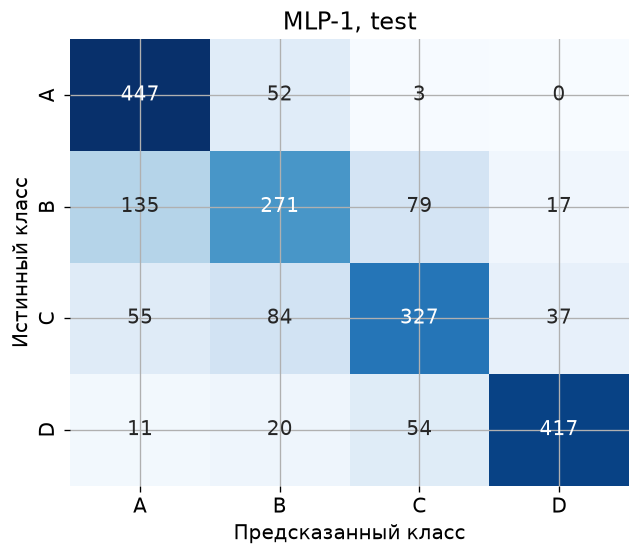

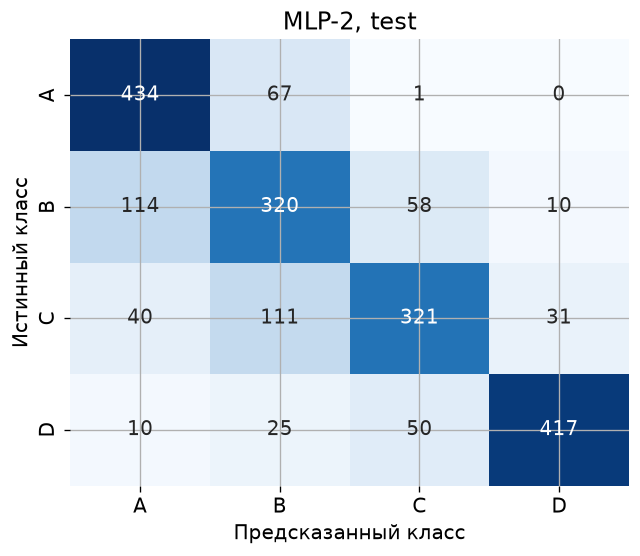

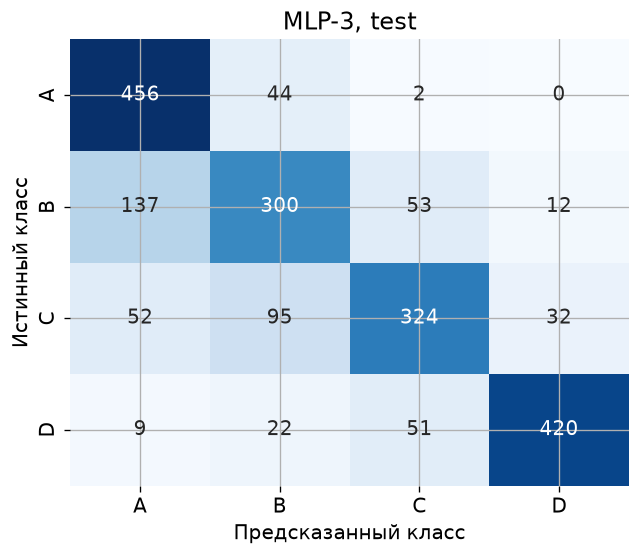

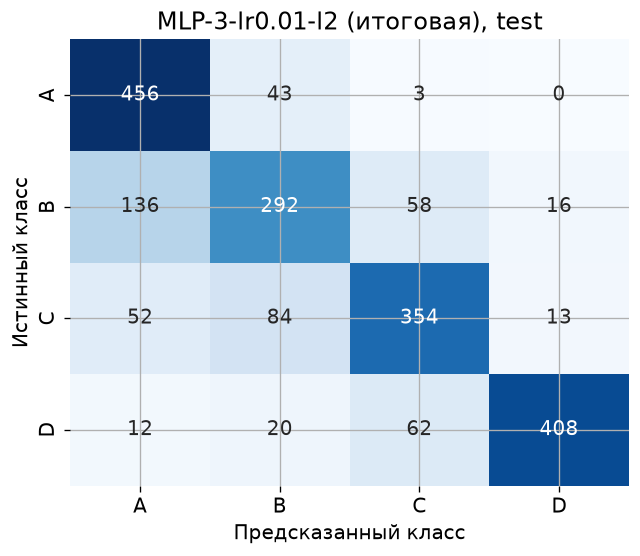

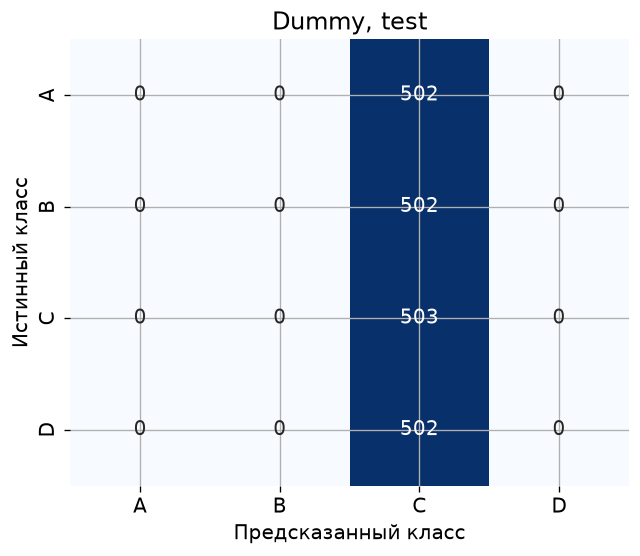

[[456  43   3   0]
 [136 292  58  16]
 [ 52  84 354  13]
 [ 12  20  62 408]]


In [30]:
for model_name in ["MLP-1", "MLP-2", "MLP-3"]:
    plot_confusion(y_test, test_probabilities_by_model[model_name], f"{model_name}, test",
                   f"multiclass-confusion-test-{model_name.lower()}.png")
plot_confusion(y_test, test_probabilities_by_model[final_name], f"{final_name} (итоговая), test",
               "multiclass-confusion-test-best.png")
plot_confusion(y_test, dummy_test_probabilities, "Dummy, test", "multiclass-confusion-test-dummy.png")

final_test_probabilities = test_probabilities_by_model[final_name]
test_matrix = confusion_matrix(y_test, final_test_probabilities.argmax(axis=1))
pd.DataFrame(test_matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
    RESULTS_DIR / "multiclass-confusion-test.csv", encoding="utf-8")
print(test_matrix)

Кривые итоговой модели с линией итогового значения на test и ROC-кривые всех классов (One-vs-Rest).

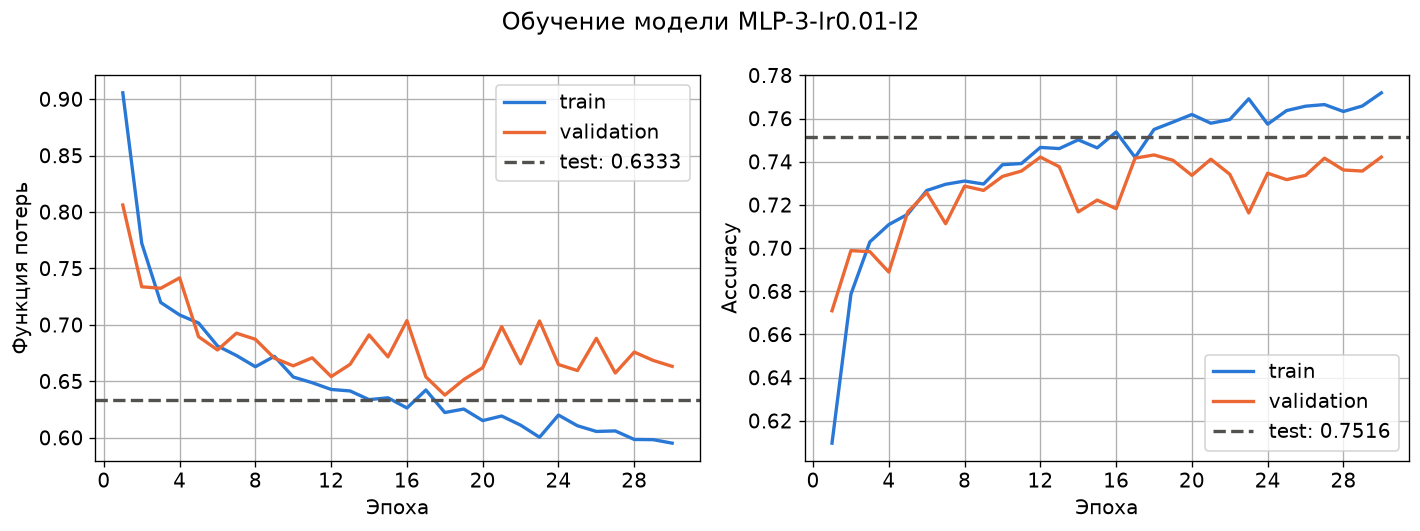

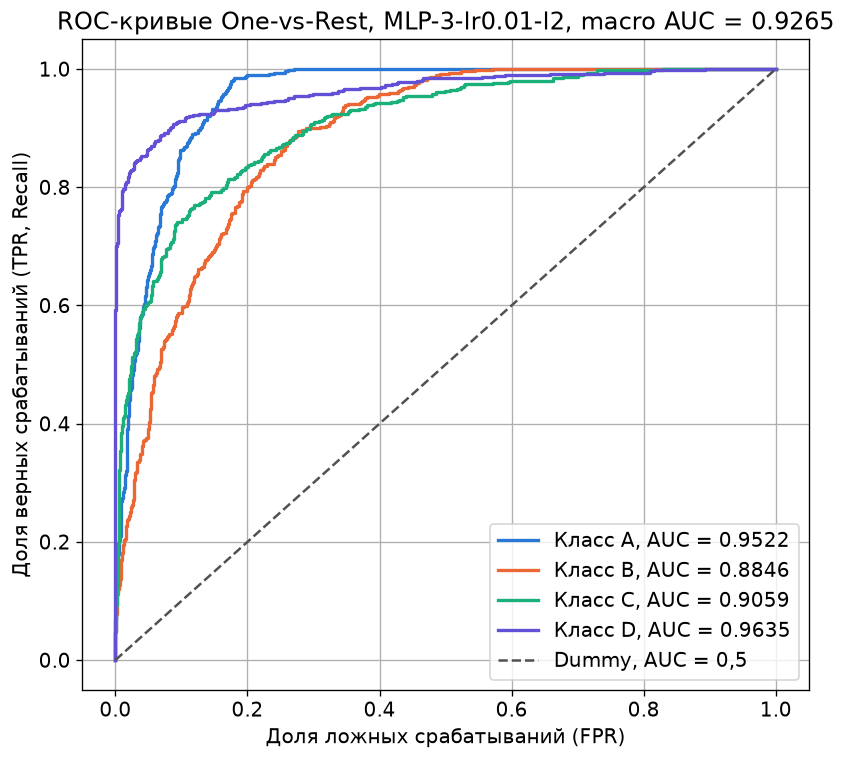

In [31]:
test_loss, test_accuracy = final_model.evaluate(X_test, y_test, batch_size=4096, verbose=0)
plot_history(final_name, "multiclass-best-history.png", test_values={"loss": test_loss, "accuracy": test_accuracy})

figure, axis = plt.subplots(figsize=(7, 6.5))
for class_index, name in enumerate(CLASS_NAMES):
    positive_mask = y_test == class_index
    false_positive_rate, true_positive_rate, _ = roc_curve(positive_mask, final_test_probabilities[:, class_index])
    class_auc = roc_auc_score(positive_mask, final_test_probabilities[:, class_index])
    axis.plot(false_positive_rate, true_positive_rate, color=CLASS_COLORS[class_index], linewidth=2,
              label=f"Класс {name}, AUC = {class_auc:.4f}")
axis.plot([0, 1], [0, 1], color=TEST_COLOR, linestyle="--", linewidth=1.5, label="Dummy, AUC = 0,5")
macro_auc = roc_auc_score(y_test, final_test_probabilities, multi_class="ovr", average="macro")
axis.set_xlabel("Доля ложных срабатываний (FPR)")
axis.set_ylabel("Доля верных срабатываний (TPR, Recall)")
axis.set_title(f"ROC-кривые One-vs-Rest, {final_name}, macro AUC = {macro_auc:.4f}")
axis.legend(loc="lower right")
figure.tight_layout()
figure.savefig(FIGURES_DIR / "multiclass-roc.png")
plt.show()

In [32]:
# Сохраняем основные архитектуры и итоговую модель для отчета и следующих лабораторных работ
for model_name in ["MLP-1", "MLP-2", "MLP-3"]:
    trained_models[model_name].save(MODELS_DIR / f"multiclass-{model_name.lower()}.keras")
final_model.save(MODELS_DIR / "multiclass-best.keras")

final_info = {"model": final_name, "class_names": CLASS_NAMES, "config": model_configs[final_name]}
with open(MODELS_DIR / "multiclass-best-info.json", "w", encoding="utf-8") as info_file:
    json.dump(final_info, info_file, ensure_ascii=False, indent=2)
print(json.dumps(final_info, ensure_ascii=False, indent=2))

{
  "model": "MLP-3-lr0.01-l2",
  "class_names": [
    "A",
    "B",
    "C",
    "D"
  ],
  "config": {
    "hidden_units": [
      256,
      128,
      64
    ],
    "activation": "relu",
    "optimizer_name": "adam",
    "learning_rate": 0.01,
    "batch_size": 128,
    "dropout_rate": 0.0,
    "l2_factor": 0.0001,
    "weighted_class": null
  }
}


**Результат:** на test итоговая модель MLP-3-lr0.01-l2 дала Accuracy 0,7516, Balanced Accuracy 0,7516, Macro F1 0,7499, Macro ROC-AUC 0,9265. Значения близки к validation (0,7432, 0,7431, 0,7413, 0,9249), значит переобучения под validation нет. `Dummy` на test: Accuracy 0,2504, Balanced Accuracy 0,25, Macro F1 0,1001, Macro ROC-AUC 0,5.

Метрики итоговой модели по классам на test:

| Класс | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|
| A | 0,6951 | 0,9084 | 0,7876 | 0,9522 |
| B | 0,6651 | 0,5817 | 0,6206 | 0,8846 |
| C | 0,7421 | 0,7038 | 0,7224 | 0,9059 |
| D | 0,9336 | 0,8127 | 0,8690 | 0,9635 |
| Macro avg | 0,7590 | 0,7516 | 0,7499 | 0,9265 |
| Weighted avg | 0,7590 | 0,7516 | 0,7499 | 0,9265 |

Значения macro и weighted совпадают, потому что классы равны по размеру.

Матрица ошибок на test подтверждает анализ: основная ошибка - 136 объектов класса B названы A и 84 объекта класса C названы B, а дальние ошибки редки (объектов класса D, названных A, всего 12, а объектов класса A, названных D, ни одного).

В таблице на test есть модели с чуть большей Balanced Accuracy, например MLP-3-no-es-dropout (0,7591), но выбор сделан по validation и после этой таблицы не меняется. На 2009 объектах такая разница лежит в пределах шума.

## Вывод

Построен многоклассовый классификатор уровня физического развития. Лучшая модель - MLP-3-lr0.01-l2: скрытые слои 256, 128 и 64 с ReLU, Adam, скорость обучения 0,01, размер пакета 128, L2 0,0001.

| Метрика на test | Итоговая модель | Dummy | Ориентир |
|---|---|---|---|
| Balanced Accuracy | 0,7516 | 0,25 | 0,80 |
| Macro ROC-AUC | 0,9265 | 0,5 | 0,80 |

**Сравнение с базовой моделью.** Модель в три раза лучше случайного угадывания по Balanced Accuracy. Macro ROC-AUC значительно выше ориентира 0,80: классы хорошо ранжируются.

**Выбор архитектуры.** Здесь сложность оправдана: от MLP-1 к MLP-3 Macro ROC-AUC вырос с 0,9105 до 0,9224 на validation, а MLP-1 явно недообучена. Дополнительный прирост дали скорость обучения 0,01 и L2.

**Переобучение.** Большая сеть без ранней остановки сильно переобучается: val loss вырастает до 0,9256. Итоговую модель от этого защищают ранняя остановка и L2. Dropout действительно устраняет переобучение у сети без ранней остановки, но при ранней остановке не дал улучшения, поэтому в итоговую модель не вошел.

**Почему Balanced Accuracy ниже 0,80.** Ранжирование хорошее (AUC 0,9265), а точный выбор класса ограничен природой данных. Классы упорядочены, значения признаков соседних классов перекрываются, поэтому большинство ошибок приходится на соседние классы, особенно на B. Попытка усилить класс B только перенесла ошибки в другие классы. Классы A-D получены разбиением непрерывной оценки физической формы на четыре равные группы, поэтому люди у границы групп почти не отличаются. Эта причина - наша гипотеза: правило присвоения класса в описании набора не приведено.

**Ограничения и возможные улучшения.** Метка присвоена по неизвестному правилу, и данные собраны только в Корее. Качество может улучшить точное правило присвоения класса или новые показатели. Другой подход - учесть порядок классов с помощью порядковой регрессии, но он выходит за рамки работы.